In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pybaseball import statcast_pitcher

# -------------------------------------------------------------------------
# 1. DOWNLOAD STATCAST DATA FOR A STARTING PITCHER
# -------------------------------------------------------------------------
# Example: MLB Player ID 607192 (Tyler Glasnow)
# You can look up any MLB ID using pybaseball.playerid_lookup('last_name', 'first_name')
pitcher_id = 607192 
df = statcast_pitcher(start_dt="2026-04-01", end_dt="2026-09-01", player_id=pitcher_id)

# Filter for primary fastballs (4-Seam / Sinker) where fatigue velocity drops show up clearest
fastballs = df[df['pitch_type'].isin(['FF', 'SI'])].copy()

# Sort chronologically by game and time
fastballs['game_date'] = pd.to_datetime(fastballs['game_date'])
fastballs = fastballs.sort_values(by=['game_date', 'at_bat_number', 'pitch_number']).reset_index(drop=True)

Gathering Player Data


In [2]:
import pandas as pd
import numpy as np

def process_pitcher_fatigue(
    df: pd.DataFrame, 
    pitch_types: list = ['FF', 'SI'], 
    max_pitch_count: int = 100
) -> pd.DataFrame:
    """
    Processes Statcast pitch data to compute true in-game pitch counts 
    and physical metric drift (velocity, release point) due to fatigue.
    """
    data = df.copy()

    # 1. Ensure strictly correct chronological pitch sequence
    sort_cols = [c for c in ['game_date', 'game_pk', 'at_bat_number', 'pitch_number'] if c in data.columns]
    data = data.sort_values(by=sort_cols, ascending=[True, True, True, True]).reset_index(drop=True)

    # 2. Group by game and pitcher to compute true in-game pitch count
    group_cols = ['game_pk']
    if 'pitcher' in data.columns:
        group_cols.append('pitcher')

    data['game_pitch_number'] = data.groupby(group_cols).cumcount() + 1

    # 3. Filter pitches up to the specified maximum limit
    fatigue_df = data[data['game_pitch_number'] <= max_pitch_count].copy()

    # 4. Filter for specific pitch types (e.g., Four-Seam Fastball 'FF', Sinker 'SI')
    target_pitches = fatigue_df[fatigue_df['pitch_type'].isin(pitch_types)].copy()

    # 5. Compute per-game baseline (average of pitches 1-15 for the targeted pitch type)
    baseline_pitches = target_pitches[target_pitches['game_pitch_number'] <= 15]
    
    game_baselines = baseline_pitches.groupby(group_cols).agg(
        baseline_velo=('release_speed', 'mean'),
        baseline_release_z=('release_pos_z', 'mean')
    ).reset_index()

    # 6. Merge baselines back and compute drift metrics
    target_pitches = target_pitches.merge(game_baselines, on=group_cols, how='left')
    target_pitches['velo_drift'] = target_pitches['release_speed'] - target_pitches['baseline_velo']
    target_pitches['release_z_drift'] = target_pitches['release_pos_z'] - target_pitches['baseline_release_z']

    return target_pitches

In [4]:
# Optional: Install pybaseball if pulling directly
# !pip install pybaseball

from pybaseball import statcast_pitcher
import pandas as pd

# Step 1: Load Statcast data (e.g., Gerrit Cole in 2023)
# Note: Raw Statcast data is delivered in REVERSE chronological order
df_raw = statcast_pitcher('2026-04-01', '2026-09-01', 680570)

#680570 Yamamoto

# Step 2: Run the fatigue processing function
fatigue_fastballs = process_pitcher_fatigue(
    df=df_raw, 
    pitch_types=['FF', 'SI'],  # Filter for fastballs/sinkers
    max_pitch_count=100
)

# Step 3: Inspect key columns
display_cols = [
    'game_date', 'game_pk', 'game_pitch_number', 
    'pitch_type', 'release_speed', 'velo_drift', 'release_z_drift'
]

Gathering Player Data


In [21]:
fatigue_fastballs[display_cols]

,game_date,game_pk,game_pitch_number,pitch_type,release_speed,velo_drift,release_z_drift
0,2026-05-17,824034,1,FF,95.4,-0.3000,-0.156667
1,2026-05-17,824034,2,FF,95.0,-0.7000,-0.106667
2,2026-05-17,824034,4,FF,94.8,-0.9000,0.113333
3,2026-05-17,824034,5,FF,96.7,1.0000,0.183333
4,2026-05-17,824034,9,FF,96.3,0.6000,-0.116667
...,...,...,...,...,...,...,...
748,2026-09-01,823984,89,FF,98.1,1.7125,-0.020000
749,2026-09-01,823984,93,FF,98.2,1.8125,0.000000
750,2026-09-01,823984,94,FF,97.0,0.6125,-0.010000
751,2026-09-01,823984,97,FF,98.0,1.6125,-0.030000


In [5]:
fatigue_summary = fatigue_fastballs.groupby('game_pitch_number').agg(
    avg_velocity=('release_speed', 'mean'),
    avg_release_z=('release_pos_z', 'mean'),
    avg_release_x=('release_pos_x', 'mean'),
    avg_spin=('release_spin_rate', 'mean'),
    sample_size=('release_speed', 'count')
).reset_index()

fatigue_summary

,game_pitch_number,avg_velocity,avg_release_z,avg_release_x,avg_spin,sample_size
0,1,94.793333,5.681333,-2.669333,2206.266667,15
1,2,94.861538,5.626923,-2.760769,2208.230769,13
2,3,95.600000,5.694286,-2.665714,2285.714286,7
3,4,95.700000,5.674444,-2.598889,2298.333333,9
4,5,96.207692,5.689231,-2.593077,2244.153846,13
...,...,...,...,...,...,...
93,94,96.620000,5.696000,-2.374000,2229.600000,5
94,95,95.850000,5.635000,-2.470000,2179.500000,2
95,96,95.350000,5.655000,-2.525000,2198.000000,2
96,97,97.850000,5.770000,-2.540000,2334.000000,2


In [6]:
# 5-pitch centered/forward rolling average for smooth trendlines
fatigue_summary['velo_rolling'] = (
    fatigue_summary['avg_velocity']
    .rolling(window=5, min_periods=1, center=True)
    .mean()
)
fatigue_summary['release_z_rolling'] = (
    fatigue_summary['avg_release_z']
    .rolling(window=5, min_periods=1, center=True)
    .mean()
)

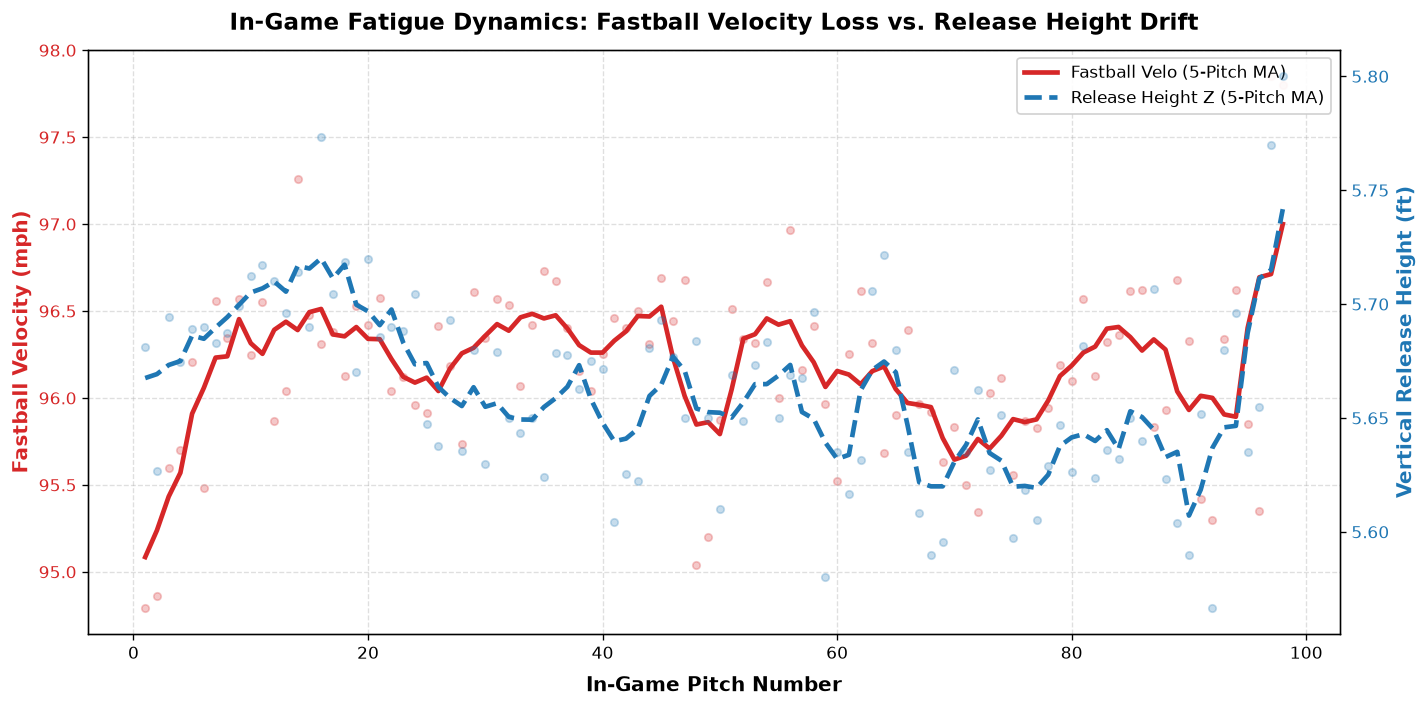

In [7]:
# =========================================================================
# 4. PLOT FATIGUE CURVES (FRONT OFFICE EXECUTIVE DELIVERABLE)
# =========================================================================
fig, ax1 = plt.subplots(figsize=(12, 6), dpi=120)

# Primary Axis: Velocity Drop
color_velo = '#D62728'  # Crisp Red
ax1.set_xlabel('In-Game Pitch Number', fontsize=12, fontweight='bold', labelpad=8)
ax1.set_ylabel('Fastball Velocity (mph)', color=color_velo, fontsize=12, fontweight='bold')

# Scatter raw pitch averages + overlay smooth rolling line
ax1.scatter(
    fatigue_summary['game_pitch_number'], 
    fatigue_summary['avg_velocity'], 
    color=color_velo, alpha=0.25, s=20, label='Raw Pitch Mean Velo'
)
line1 = ax1.plot(
    fatigue_summary['game_pitch_number'], 
    fatigue_summary['velo_rolling'], 
    color=color_velo, linewidth=2.8, label='Fastball Velo (5-Pitch MA)'
)
ax1.tick_params(axis='y', labelcolor=color_velo, labelsize=10)
ax1.grid(True, linestyle='--', alpha=0.4)

# Secondary Axis: Vertical Release Height (Arm Slot Drop)
ax2 = ax1.twinx()  
color_z = '#1F77B4'  # Deep Blue
ax2.set_ylabel('Vertical Release Height (ft)', color=color_z, fontsize=12, fontweight='bold')

ax2.scatter(
    fatigue_summary['game_pitch_number'], 
    fatigue_summary['avg_release_z'], 
    color=color_z, alpha=0.25, s=20
)
line2 = ax2.plot(
    fatigue_summary['game_pitch_number'], 
    fatigue_summary['release_z_rolling'], 
    color=color_z, linewidth=2.8, linestyle='--', label='Release Height Z (5-Pitch MA)'
)
ax2.tick_params(axis='y', labelcolor=color_z, labelsize=10)

# Combined Legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

plt.title(
    'In-Game Fatigue Dynamics: Fastball Velocity Loss vs. Release Height Drift', 
    fontsize=14, fontweight='bold', pad=12
)
fig.tight_layout()
plt.show()

In [12]:
!pip install pymc

  Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl.metadata (6.6 kB)
Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl (5.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ortools 9.11.4210 requires protobuf<5.27,>=5.26.1, but you have protobuf 4.25.9 which is incompatible.
flax 0.12.2 requires jax>=0.8.1, but you have jax 0.7.1 which is incompatible.
langchain-chroma 1.1.0 requires chromadb<2.0.0,>=1.3.5, but you have chromadb 1.1.1 which is incompatible.
tensorflow 2.20.0 requires protobuf>=5.28.0, but you have protobuf 4.25.9 which is incompatible.
mediapipe 0.10.21 requires numpy<2, but you have numpy 2.4.6 which is incompatible.
streamlit 1.51.0 requires packaging<26,>=20, but you have

In [1]:
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

/Users/jinzhixu/spark-env/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [8]:
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

pymc_data = fatigue_summary.dropna(subset=['avg_velocity']).sort_values('game_pitch_number').reset_index(drop=True)
x_pitches = pymc_data['game_pitch_number'].values
y_velo = pymc_data['avg_velocity'].values
N = len(x_pitches)

with pm.Model() as fatigue_change_point_model:
    # Discrete prior for unknown change-point index
    tau = pm.DiscreteUniform('tau', lower=10, upper=N - 10)
    
    # Gaussian priors for pre- and post-fatigue fastball velocities
    mu_1 = pm.Normal('mu_1', mu=y_velo[:20].mean(), sigma=2.0)
    mu_2 = pm.Normal('mu_2', mu=y_velo[-20:].mean(), sigma=2.0)
    
    sigma = pm.HalfNormal('sigma', sigma=1.0)
    
    idx = np.arange(N)
    mu = pm.math.switch(tau > idx, mu_1, mu_2)
    
    likelihood = pm.Normal('y_obs', mu=mu, sigma=sigma, observed=y_velo)
    
    idata = pm.sample(draws=2000, tune=1000, return_inferencedata=True, random_seed=42)

# Extract MCMC summary statistics
tau_samples = idata.posterior['tau'].values.flatten()
pitch_threshold_samples = x_pitches[tau_samples]

most_likely_pitch = int(np.median(pitch_threshold_samples))
hdi_bounds = az.hdi(pitch_threshold_samples, hdi_prob=0.95)

mu1_mean = idata.posterior['mu_1'].mean().values.item()
mu2_mean = idata.posterior['mu_2'].mean().values.item()
velo_drop = mu1_mean - mu2_mean

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [tau]
>NUTS: [mu_1, mu_2, sigma]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.
There were 8 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


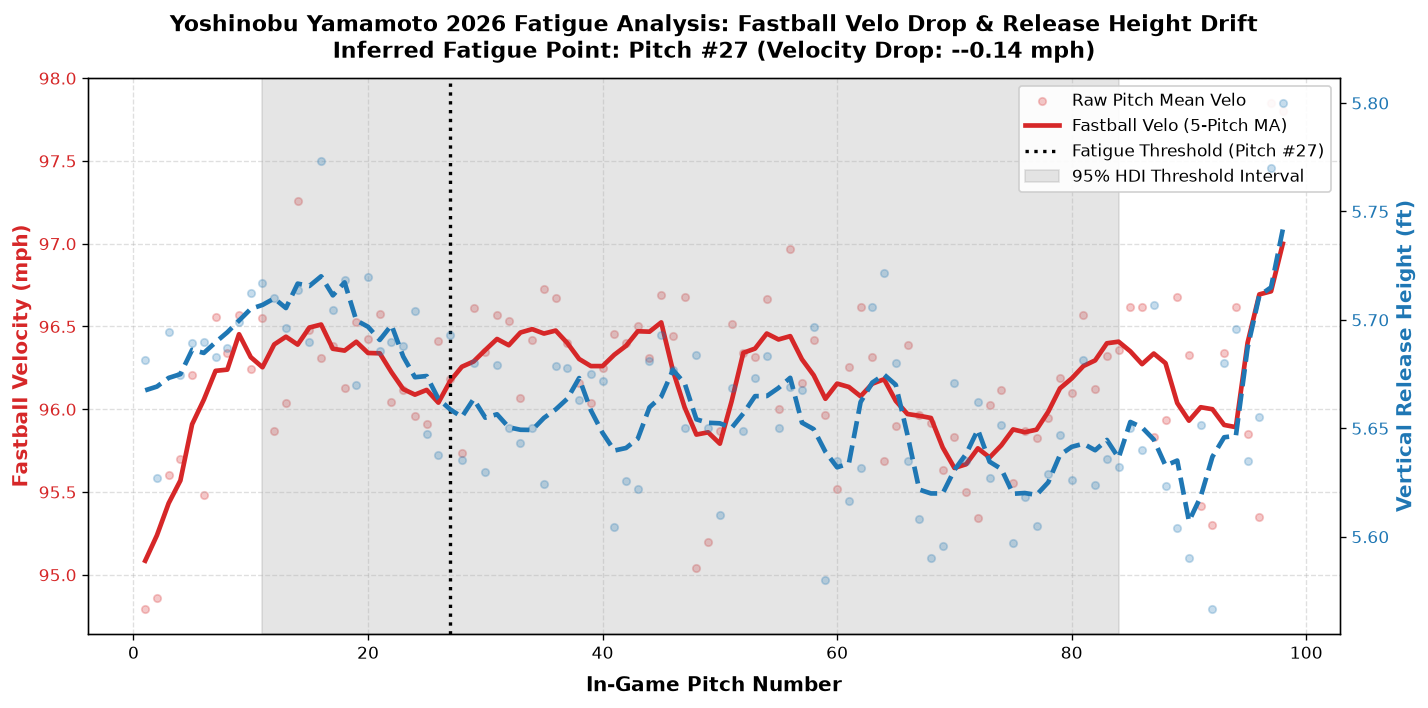


 Yamamoto 2026 Bayesian Change-Point Summary 
Inferred Fatigue Change-Point:    Pitch #27
95% High-Density Interval (HDI): Pitch #11 to #84
Pre-Fatigue Fastball Velo (mu_1):  96.06 mph
Post-Fatigue Fastball Velo (mu_2): 96.20 mph
Velocity Degradation:             --0.14 mph


In [9]:
# =========================================================================
# 4. PLOT FATIGUE CURVE WITH OVERLAID CHANGE-POINT & 95% HDI
# =========================================================================
fig, ax1 = plt.subplots(figsize=(12, 6), dpi=120)

color_velo = '#D62728'  # Red
ax1.set_xlabel('In-Game Pitch Number', fontsize=12, fontweight='bold', labelpad=8)
ax1.set_ylabel('Fastball Velocity (mph)', color=color_velo, fontsize=12, fontweight='bold')

ax1.scatter(
    fatigue_summary['game_pitch_number'], 
    fatigue_summary['avg_velocity'], 
    color=color_velo, alpha=0.25, s=20, label='Raw Pitch Mean Velo'
)
line1 = ax1.plot(
    fatigue_summary['game_pitch_number'], 
    fatigue_summary['velo_rolling'], 
    color=color_velo, linewidth=2.8, label='Fastball Velo (5-Pitch MA)'
)
ax1.tick_params(axis='y', labelcolor=color_velo, labelsize=10)
ax1.grid(True, linestyle='--', alpha=0.4)

# Vertical Release Height (Right Y-Axis)
ax2 = ax1.twinx()  
color_z = '#1F77B4'  # Blue
ax2.set_ylabel('Vertical Release Height (ft)', color=color_z, fontsize=12, fontweight='bold')

ax2.scatter(
    fatigue_summary['game_pitch_number'], 
    fatigue_summary['avg_release_z'], 
    color=color_z, alpha=0.25, s=20
)
line2 = ax2.plot(
    fatigue_summary['game_pitch_number'], 
    fatigue_summary['release_z_rolling'], 
    color=color_z, linewidth=2.8, linestyle='--', label='Release Height Z (5-Pitch MA)'
)
ax2.tick_params(axis='y', labelcolor=color_z, labelsize=10)

# Overlay Bayesian Change-Point Line and Shaded 95% HDI Region
ax1.axvline(
    x=most_likely_pitch, color='black', linestyle=':', linewidth=2, 
    label=f'Fatigue Threshold (Pitch #{most_likely_pitch})'
)
ax1.axvspan(
    hdi_bounds[0], hdi_bounds[1], color='gray', alpha=0.2, 
    label='95% HDI Threshold Interval'
)

# Combined Legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
handles, labels_all = ax1.get_legend_handles_labels()
ax1.legend(handles, labels_all, loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

plt.title(
    f'Yoshinobu Yamamoto 2026 Fatigue Analysis: Fastball Velo Drop & Release Height Drift\n'
    f'Inferred Fatigue Point: Pitch #{most_likely_pitch} (Velocity Drop: -{velo_drop:.2f} mph)', 
    fontsize=13, fontweight='bold', pad=12
)
fig.tight_layout()
plt.show()

# Printed Executive Summary
print("\n" + "="*55)
print(" Yamamoto 2026 Bayesian Change-Point Summary ")
print("="*55)
#print(f"Pitcher ID:                       {YAMAMOTO_ID} (Yoshinobu Yamamoto)")
print(f"Inferred Fatigue Change-Point:    Pitch #{most_likely_pitch}")
print(f"95% High-Density Interval (HDI): Pitch #{int(hdi_bounds[0])} to #{int(hdi_bounds[1])}")
print(f"Pre-Fatigue Fastball Velo (mu_1):  {mu1_mean:.2f} mph")
print(f"Post-Fatigue Fastball Velo (mu_2): {mu2_mean:.2f} mph")
print(f"Velocity Degradation:             -{velo_drop:.2f} mph")
print("="*55)